# Basis-independent Kirkwood-Dirac nonclassicality: certification and a robust contextuality test

**Companion notebook.** This notebook reproduces every numerical value and every figure of the manuscript, in the order in which they appear. Each section refers to the corresponding section, equation, figure or table of the paper. It is self-contained and needs only `numpy`, `scipy` and `matplotlib`. Figures are typeset with LaTeX when a LaTeX installation is found, and with matplotlib's built-in mathtext otherwise. Running all cells takes a few minutes, dominated by the order-12 word enumeration of Sec. III H and by Fig. 5(b).

Conventions used throughout: $|0\rangle=|H\rangle$, $|1\rangle=|V\rangle$, $|\pm\rangle=(|0\rangle\pm|1\rangle)/\sqrt2$, and a Bargmann invariant of a word $w=i_1\cdots i_m$ is $\Delta_w=\mathrm{Tr}(\rho_{i_1}\cdots\rho_{i_m})$.

In [2]:
import itertools, shutil, time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle, Circle, Ellipse
from scipy.stats import norm
from scipy.optimize import minimize_scalar, brentq, minimize

np.set_printoptions(precision=6, suppress=True)
rng = np.random.default_rng(2026)

USETEX = shutil.which('latex') is not None
plt.rcParams.update({'text.usetex': USETEX, 'font.family': 'serif', 'font.size': 10,
                     'axes.labelsize': 10, 'legend.fontsize': 9, 'xtick.labelsize': 9, 'ytick.labelsize': 9})
if USETEX:
    plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}\usepackage{amssymb}'
else:
    plt.rcParams['mathtext.fontset'] = 'cm'
BLUE, ORANGE, GREEN, RED, PURPLE = '#1f4e9c', '#d97706', '#1d7a1d', '#b91c1c', '#7c3aed'

def save(fig, name):
    fig.savefig(name + '.pdf', bbox_inches='tight', pad_inches=0.03)
    fig.savefig(name + '.png', dpi=150, bbox_inches='tight', pad_inches=0.03)

def letter(ax, x, y, s, c='k', fs=9, fc='white'):
    ax.text(x, y, s, ha='center', va='center', fontsize=fs, color=c, zorder=6,
            bbox=dict(boxstyle='circle,pad=0.18', fc=fc, ec=c, lw=1.0))

# ---------- basic quantum objects ----------
I2 = np.eye(2)
sx = np.array([[0, 1], [1, 0]], complex); sy = np.array([[0, -1j], [1j, 0]]); sz = np.array([[1, 0], [0, -1]], complex)
k0, k1 = np.array([1, 0], complex), np.array([0, 1], complex)
kp, km = (k0 + k1) / np.sqrt(2), (k0 - k1) / np.sqrt(2)
proj = lambda v: np.outer(v, np.conj(v))
def bloch_state(r):
    return 0.5 * (I2 + r[0] * sx + r[1] * sy + r[2] * sz)
def random_pure(d):
    v = rng.normal(size=d) + 1j * rng.normal(size=d); return v / np.linalg.norm(v)
def random_mixed(d, rank=None):
    rank = rank or d
    X = rng.normal(size=(d, rank)) + 1j * rng.normal(size=(d, rank)); R = X @ X.conj().T
    return R / np.trace(R).real

# ---------- Bargmann invariants of words ----------
def invariant(states, word):
    M = np.eye(states[0].shape[0], dtype=complex)
    for i in word: M = M @ states[i]
    return np.trace(M)

def necklaces(n, L):
    # one representative of every word of length 1..L up to cyclic rotation
    out = set()
    for m in range(1, L + 1):
        for w in itertools.product(range(n), repeat=m):
            out.add(min(w[i:] + w[:i] for i in range(m)))
    return sorted(out, key=lambda w: (len(w), w))

def all_invariants(states, L):
    return {w: invariant(states, w) for w in necklaces(len(states), L)}

def in_KC(states, L, tol=1e-12):
    # True if every invariant of order <= L is real and nonnegative
    for w, t in all_invariants(states, L).items():
        if t.real < -tol or abs(t.imag) > tol: return False
    return True

## Sec. II C: Measuring Bargmann invariants (cycle test, Fig. 1, Appendix A)

We simulate the circuit of Fig. 1 exactly. An ancilla in $|+\rangle$ controls a cyclic shift $S$ of $m$ registers holding $\rho_{i_1},\dots,\rho_{i_m}$. Appendix A shows $\langle X\rangle+i\langle Y\rangle=\mathrm{Tr}(S\sigma)=\mathrm{Tr}(\rho_{i_m}\cdots\rho_{i_1})$, which is the Bargmann invariant of the reversed word and equals the complex conjugate of $\Delta_{i_1\cdots i_m}$ by Eq. (5). We check this for random mixed qutrit states with $m=3$, and for $m=2$, where the circuit is the swap test.

In [4]:
def cyclic_shift(d, m):
    # S|k1 k2 ... km> = |km k1 ... k_{m-1}>, so that S^dagger |k1...km> = |k2...km k1>
    D = d ** m; S = np.zeros((D, D))
    for idx in range(D):
        ks = np.unravel_index(idx, (d,) * m)
        new = (ks[-1],) + ks[:-1]
        S[np.ravel_multi_index(new, (d,) * m), idx] = 1
    return S

def cycle_test(states):
    d, m = states[0].shape[0], len(states)
    sigma = states[0]
    for s in states[1:]: sigma = np.kron(sigma, s)
    S = cyclic_shift(d, m); D = d ** m
    CS = np.block([[np.eye(D), np.zeros((D, D))], [np.zeros((D, D)), S]])
    plus = proj(kp)
    Omega = CS @ np.kron(plus, sigma) @ CS.conj().T
    X = np.kron(sx, np.eye(D)); Y = np.kron(sy, np.eye(D))
    return np.trace(X @ Omega).real, np.trace(Y @ Omega).real

for m in (2, 3):
    st = [random_mixed(3) for _ in range(m)]
    ex, ey = cycle_test(st)
    target = invariant(st, list(range(m))[::-1])
    print(f"m={m}: <X>+i<Y> = {ex:+.10f}{ey:+.10f}i,  Tr(rho_m...rho_1) = {target:.10f},  "
          f"difference = {abs(ex + 1j*ey - target):.1e}")

m=2: <X>+i<Y> = +0.3326915481+0.0000000000i,  Tr(rho_m...rho_1) = 0.3326915481+0.0000000000j,  difference = 1.1e-16
m=3: <X>+i<Y> = +0.0680684107-0.0297878885i,  Tr(rho_m...rho_1) = 0.0680684107-0.0297878885j,  difference = 1.6e-17


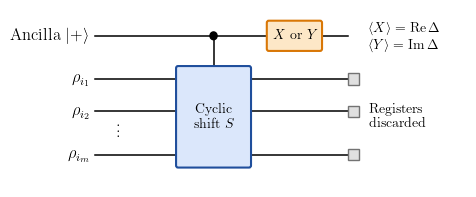

In [75]:
# ---------- Fig. 1: cycle test ----------
fig, ax = plt.subplots(figsize=(5.6, 2.3)); ax.set_xlim(0, 11); ax.set_ylim(0.2, 4.3); ax.axis('off')
ys = [3.7, 2.7, 1.95, 0.95]; labs = [r'Ancilla $|+\rangle$', r'$\rho_{i_1}$', r'$\rho_{i_2}$', r'$\rho_{i_m}$']
for y, l in zip(ys, labs):
    ax.plot([1.6, 8.0], [y, y], color='k', lw=1.1, zorder=1); ax.text(1.45, y, l, ha='right', va='center', fontsize=12)
ax.text(2.2, 1.45, r'$\vdots$', ha='center', va='center', fontsize=12)
ax.plot([4.6, 4.6], [2.95, 3.7], color='k', lw=1.1, zorder=1); ax.add_patch(Circle((4.6, 3.7), 0.09, color='k', zorder=4))
ax.add_patch(FancyBboxPatch((3.7, 0.7), 1.8, 2.25, boxstyle='round,pad=0.05', fc='#dbe7fb', ec=BLUE, lw=1.5, zorder=3))
ax.text(4.6, 1.82, r'Cyclic' + '\n' + r'\center shift $S$', ha='center', va='center', color='black', zorder=4, fontsize=10)
ax.add_patch(FancyBboxPatch((6.0, 3.4), 1.3, 0.6, boxstyle='round,pad=0.05', fc='#fde7c7', ec=ORANGE, lw=1.5, zorder=3))
ax.text(6.65, 3.7, r'$X$ or $Y$', ha='center', va='center', zorder=4)
for y in ys[1:]: ax.add_patch(Rectangle((8.0, y - 0.13), 0.28, 0.26, fc='0.88', ec='0.45', zorder=3))
ax.text(8.55, 3.7, r'$\langle X\rangle=\mathrm{Re}\,\Delta$', ha='left', va='bottom', fontsize=10)
ax.text(8.55, 3.62, r'$\langle Y\rangle=\mathrm{Im}\,\Delta$', ha='left', va='top', fontsize=10)
ax.text(8.55, 1.82, 'Registers\ndiscarded', ha='left', va='center', color='0.0', fontsize=10)
save(fig, 'fig1'); plt.show()

## Sec. III B: Invariants that are always nonnegative (Lemma 1, Eq. (14))

Lemma 1 states that nearly symmetric words have nonnegative invariants for every tuple of states. Eq. (14) lists the two-letter words up to order five, which are all nearly symmetric. We check numerically that their invariants are real and nonnegative for many random pairs of mixed states in dimensions two to four, while a generic word of length three in three letters is not.

In [7]:
two_letter = [w for w in necklaces(2, 5) if len(set(w)) == 2]
print("Two-letter necklaces up to order 5:", [''.join(str(i + 1) for i in w) for w in two_letter])
worst_re, worst_im = np.inf, 0.0
for _ in range(3000):
    d = rng.integers(2, 5); st = [random_mixed(d), random_mixed(d)]
    for w in two_letter:
        t = invariant(st, w); worst_re = min(worst_re, t.real); worst_im = max(worst_im, abs(t.imag))
print(f"3000 random pairs: smallest real part = {worst_re:.3e} (>= 0), largest |imaginary part| = {worst_im:.1e}")
t = invariant([random_mixed(3) for _ in range(3)], (0, 1, 2))
print(f"For comparison, Tr(rho1 rho2 rho3) for three random qutrit states: {t:.4f}")

Two-letter necklaces up to order 5: ['12', '112', '122', '1112', '1122', '1212', '1222', '11112', '11122', '11212', '11222', '12122', '12222']
3000 random pairs: smallest real part = 7.670e-05 (>= 0), largest |imaginary part| = 5.6e-17
For comparison, Tr(rho1 rho2 rho3) for three random qutrit states: 0.1291+0.0207j


## Sec. III D: A hierarchy of basis-independent resources (Theorem 1, Eqs. (16)-(18), Fig. 2)

Two pure states with $0<|c|<1$ are set coherent but KD classical, since every invariant equals $|c|^{2r}$ by Eq. (16). The qubit trine of Eq. (17) is set real but KD nonclassical, with $\Delta_{123}=-1/8$ by Eq. (18).

In [9]:
psi1, psi2 = random_pure(3), random_pure(3)
pair = [proj(psi1), proj(psi2)]; c = np.vdot(psi1, psi2)
print("Two pure states: |c| =", round(abs(c), 6), "  commutator norm =",
      round(np.linalg.norm(pair[0] @ pair[1] - pair[1] @ pair[0]), 6))
for r in range(1, 5):
    print(f"  Delta_(12)^{r} = {invariant(pair, (0, 1) * r).real:.8f},   |c|^(2r) = {abs(c)**(2*r):.8f}")
print("  KD classical up to order 8:", in_KC(pair, 8))

trine = [proj(np.array([np.cos(t), np.sin(t)], complex)) for t in (0, np.pi / 3, 2 * np.pi / 3)]
G = np.array([[np.cos(b - a) for b in (0, np.pi/3, 2*np.pi/3)] for a in (0, np.pi/3, 2*np.pi/3)])
print("\nTrine Gram matrix:\n", G)
print("Trine Delta_123 =", np.round(invariant(trine, (0, 1, 2)), 12), " (expected -1/8 =", -1/8, ")")

Two pure states: |c| = 0.68976   commutator norm = 0.706276
  Delta_(12)^1 = 0.47576884,   |c|^(2r) = 0.47576884
  Delta_(12)^2 = 0.22635599,   |c|^(2r) = 0.22635599
  Delta_(12)^3 = 0.10769312,   |c|^(2r) = 0.10769312
  Delta_(12)^4 = 0.05123703,   |c|^(2r) = 0.05123703
  KD classical up to order 8: True

Trine Gram matrix:
 [[ 1.   0.5 -0.5]
 [ 0.5  1.   0.5]
 [-0.5  0.5  1. ]]
Trine Delta_123 = (-0.125+0j)  (expected -1/8 = -0.125 )


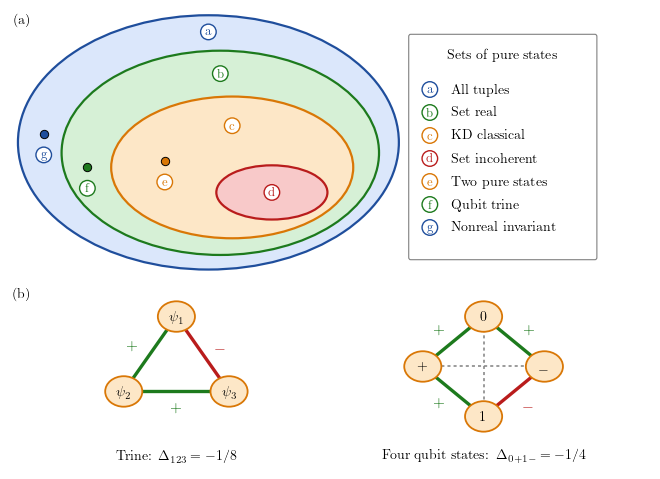

In [77]:
# ---------- Fig. 2: hierarchy and signed overlap graphs ----------
fig = plt.figure(figsize=(6.4, 4.6))
ax = fig.add_axes([0, 0.42, 0.62, 0.58]); ax.set_xlim(0, 10); ax.set_ylim(0, 6.4); ax.axis('off')
spec = [(5, 3.2, 9.6, 6.1, '#dbe7fb', BLUE, 'a', (5, 5.85)), (5.3, 2.95, 8.0, 4.9, '#d6f0d6', GREEN, 'b', (5.3, 4.85)),
        (5.6, 2.6, 6.1, 3.4, '#fde7c7', ORANGE, 'c', (5.6, 3.6)), (6.6, 2.0, 2.8, 1.3, '#f8c9c9', RED, 'd', (6.6, 2.0))]
for x, y, w, h, fc, ec, l, t in spec:
    ax.add_patch(Ellipse((x, y), w, h, fc=fc, ec=ec, lw=1.6)); letter(ax, *t, l, ec)
for x, y, l, c in [(0.85, 3.4, 'g', BLUE), (1.95, 2.6, 'f', GREEN), (3.9, 2.75, 'e', ORANGE)]:
    ax.plot(x, y, 'o', color=c, ms=6, mec='k', mew=0.7, zorder=5); letter(ax, x, y - 0.5, l, c)
ax.text(0.1, 6.3, r'(a)', fontsize=10, va='top')
lg = fig.add_axes([0.62, 0.45, 0.3, 0.5]); lg.axis('off'); lg.set_xlim(0, 1); lg.set_ylim(0, 1)
lg.add_patch(FancyBboxPatch((0.02, 0.02), 0.96, 0.96, boxstyle='round,pad=0.01', fc='white', ec='0.5', lw=0.8))
lg.text(0.5, 0.9, 'Sets of pure states', ha='center', va='center', fontsize=10, weight='bold')
items = [('a', BLUE, 'All tuples'), ('b', GREEN, 'Set real'), ('c', ORANGE, 'KD classical'), ('d', RED, 'Set incoherent'),
         ('e', ORANGE, 'Two pure states'), ('f', GREEN, 'Qubit trine'), ('g', BLUE, 'Nonreal invariant')]
for k, (l, c, t) in enumerate(items):
    y = 0.75 - k * 0.1; letter(lg, 0.12, y, l, c); lg.text(0.23, y, t, va='center', fontsize=10)
bx = fig.add_axes([0, 0, 1, 0.4]); bx.set_xlim(0, 10); bx.set_ylim(0, 3.5); bx.axis('off')
bx.text(0.05, 3.45, r'(b)', fontsize=10, va='top')
def graph(cx, cy, R, labels, signs, title, zero=()):
    n = len(labels); ang = [np.pi/2 + 2*np.pi*k/n for k in range(n)]; P = [(cx + R*np.cos(a), cy + R*np.sin(a)) for a in ang]
    for k in range(n):
        a, b = P[k], P[(k + 1) % n]; s = signs[k]; c = GREEN if s > 0 else RED
        bx.plot([a[0], b[0]], [a[1], b[1]], color=c, lw=2.4, zorder=1)
        mx, my = (a[0] + b[0]) / 2, (a[1] + b[1]) / 2; dx, dy = mx - cx, my - cy; nr = np.hypot(dx, dy)
        bx.text(mx + 0.32*dx/nr, my + 0.32*dy/nr, '$+$' if s > 0 else '$-$', ha='center', va='center', color=c, fontsize=11)
    for i, j in zero: bx.plot([P[i][0], P[j][0]], [P[i][1], P[j][1]], ls=(0, (2, 2)), color='0.5', lw=1.1, zorder=1)
    for p, l in zip(P, labels):
        bx.add_patch(Circle(p, 0.29, fc='#fde7c7', ec=ORANGE, lw=1.3, zorder=3)); bx.text(*p, l, ha='center', va='center', zorder=4)
    bx.text(cx, cy - R - 0.75, title, ha='center', va='center')
graph(2.6, 1.95, 0.95, [r'$\psi_1$', r'$\psi_2$', r'$\psi_3$'], [1, 1, -1], r'Trine: $\Delta_{123}=-1/8$')
graph(7.4, 1.95, 0.95, [r'$0$', r'$+$', r'$1$', r'$-$'], [1, 1, -1, 1], r'Four qubit states: $\Delta_{0+1-}=-1/4$', zero=[(0, 2), (1, 3)])
save(fig, 'fig2'); plt.show()

## Sec. III E: Pure states and geometric phases (Theorem 2, Eq. (20), Fig. 3)

For the overlap graph of Fig. 3, $|E|=7$, $n=6$ and $c=1$, so $\beta(H)=2$. We realize this graph by six pure states in $\mathbb{C}^6$, with Gram matrix $G=\mathbb 1+tA$ for a signed adjacency matrix $A$, and test Theorem 2 in both directions. When the two fundamental loop invariants are positive, the tree rephasing of the proof makes $G$ entrywise nonnegative and all invariants up to order six are nonnegative. When one fundamental loop carries a negative sign, a negative invariant appears, as the theorem predicts.

In [12]:
edges = [(1, 2), (1, 3), (2, 4), (4, 5), (4, 6), (3, 4), (5, 6)]       # tree edges first, then the two extra edges
tree = edges[:5]
n, E = 6, len(edges); ccomp = 1
print(f"|E| = {E}, n = {n}, c = {ccomp},  beta(H) = |E| - n + c = {E - n + ccomp}")

def states_from_gram(Gm):
    w, V = np.linalg.eigh(Gm); assert w.min() > 0
    Vm = np.diag(np.sqrt(w)) @ V.conj().T          # Vm^dagger Vm = Gm, columns are the state vectors
    return [Vm[:, i] for i in range(Gm.shape[0])]

def build(signs, t=0.3, phases=None):
    A = np.zeros((6, 6), complex)
    for (i, j), s in zip(edges, signs): A[i-1, j-1] = s; A[j-1, i-1] = s
    Gm = np.eye(6) + t * A
    if phases is not None:                         # random rephasing hides the structure
        D = np.diag(np.exp(1j * phases)); Gm = D.conj() @ Gm @ D
    vecs = states_from_gram(Gm)
    return vecs, [proj(v) for v in vecs]

def tree_path(i, j):
    # path from j back to i along the tree (breadth-first search)
    adj = {k: [] for k in range(1, 7)}
    for a, b in tree: adj[a].append(b); adj[b].append(a)
    prev, queue = {j: None}, [j]
    while queue:
        x = queue.pop(0)
        for y in adj[x]:
            if y not in prev: prev[y] = x; queue.append(y)
    path, x = [], i
    while x is not None: path.append(x); x = prev[x]
    return path[::-1]                               # j, ..., i

def fundamental_loop_invariants(states):
    out = {}
    for (i, j) in edges[5:]:
        p = tree_path(i, j)                         # j = p0, ..., p_l = i
        word = [i - 1] + [q - 1 for q in p[:-1]]    # i, j, p1, ..., p_{l-1}
        out[(i, j)] = (word, invariant(states, word))
    return out

def rephase_tree(vecs):
    # proof of Theorem 2, (iv) => (iii): walk away from the root and make every tree overlap positive
    v = [x.copy() for x in vecs]; done = {1}
    while len(done) < 6:
        for a, b in tree:
            for i, j in ((a, b), (b, a)):
                if i in done and j not in done:
                    g = np.vdot(v[i-1], v[j-1]); v[j-1] *= np.conj(g) / abs(g); done.add(j)
    return np.array([[np.vdot(x, y) for y in v] for x in v])

for label, signs in [("all overlaps positive", [1]*7), ("one negative edge in a loop", [1, 1, 1, 1, 1, -1, 1])]:
    vecs, st = build(signs, phases=rng.uniform(0, 2*np.pi, 6))
    loops = fundamental_loop_invariants(st)
    print(f"\n{label}:")
    for e, (w, val) in loops.items():
        print(f"  fundamental loop of edge {e}: word {[x + 1 for x in w]}, invariant = {val:.6f}")
    Gr = rephase_tree(vecs)
    print("  smallest real part of an entry of the tree-rephased Gram matrix:", round(Gr.real.min(), 6),
          ", largest |imag|:", f"{abs(Gr.imag).max():.1e}")
    inv = all_invariants(st, 6)
    worst = min(inv.items(), key=lambda kv: kv[1].real)
    print(f"  {len(inv)} invariants up to order 6, smallest real part {worst[1].real:+.6f} for word {[x + 1 for x in worst[0]]}")
    print("  KD classical up to order 6:", in_KC(st, 6))
print("\nFor n states with all overlaps nonzero, (n-1)(n-2)/2 triangle invariants decide; for n = 6 this is", 5 * 4 // 2)

|E| = 7, n = 6, c = 1,  beta(H) = |E| - n + c = 2

all overlaps positive:
  fundamental loop of edge (3, 4): word [3, 4, 2, 1], invariant = 0.008100+0.000000j
  fundamental loop of edge (5, 6): word [5, 6, 4], invariant = 0.027000+0.000000j
  smallest real part of an entry of the tree-rephased Gram matrix: -0.0 , largest |imag|: 1.9e-16
  9825 invariants up to order 6, smallest real part -0.000000 for word [1, 1, 2, 3, 3]
  KD classical up to order 6: True

one negative edge in a loop:
  fundamental loop of edge (3, 4): word [3, 4, 2, 1], invariant = -0.008100-0.000000j
  fundamental loop of edge (5, 6): word [5, 6, 4], invariant = 0.027000-0.000000j
  smallest real part of an entry of the tree-rephased Gram matrix: -0.3 , largest |imag|: 1.7e-16
  9825 invariants up to order 6, smallest real part -0.008100 for word [1, 3, 4, 4, 4, 2]
  KD classical up to order 6: False

For n states with all overlaps nonzero, (n-1)(n-2)/2 triangle invariants decide; for n = 6 this is 10


  9825 invariants up to order 6, smallest real part -0.008100 for word [1, 2, 4, 3]
  KD classical up to order 6: False

For n states with all overlaps nonzero, (n-1)(n-2)/2 triangle invariants decide; for n = 6 this is 10


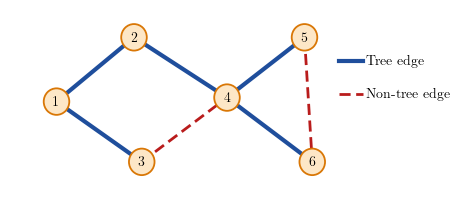

In [79]:
# ---------- Fig. 3: spanning tree and fundamental loops ----------
fig, ax = plt.subplots(figsize=(5.0, 2.4)); ax.set_xlim(0, 10); ax.set_ylim(0, 4.6); ax.axis('off')
pos = {1: (1.2, 2.3), 2: (3.2, 3.9), 3: (3.4, 0.8), 4: (5.6, 2.4), 5: (7.6, 3.9), 6: (7.8, 0.8)}
for i, j in tree: ax.plot(*zip(pos[i], pos[j]), color=BLUE, lw=3, zorder=1)
for i, j in edges[5:]: ax.plot(*zip(pos[i], pos[j]), color=RED, lw=2, ls=(0, (4, 2)), zorder=1)
for k, p in pos.items():
    ax.add_patch(Circle(p, 0.33, fc='#fde7c7', ec=ORANGE, lw=1.3, zorder=3)); ax.text(*p, r'$%d$' % k, ha='center', va='center', zorder=4)
ax.plot([8.5, 9.1], [3.3, 3.3], color=BLUE, lw=3); ax.text(9.2, 3.3, 'Tree edge', va='center', fontsize=10)
ax.plot([8.5, 9.1], [2.5, 2.5], color=RED, lw=2, ls=(0, (4, 2))); ax.text(9.2, 2.5, 'Non-tree edge', va='center', fontsize=10)
save(fig, 'fig3'); plt.show()

## Sec. III F: Beyond the ordinary distribution (Theorem 3, Eqs. (22)-(25))

The signed-cycle construction $G=\mathbb 1+tA$ of Eq. (22) gives $k$ pure states in $\mathbb C^k$ that are in $\mathrm{KC}_{k-1}$ but not in $\mathrm{KC}_k$. We check this by enumerating all words up to length $k$ for $k=3,\dots,6$, and verify $\Delta_{12\cdots k}=-t^k$. Then we treat the qubit states $|0\rangle,|+\rangle,|1\rangle,|-\rangle$ of Eq. (25).

In [15]:
t = 0.3
for k in range(3, 7):
    A = np.zeros((k, k))
    for i in range(k - 1): A[i, i+1] = A[i+1, i] = 1
    A[k-1, 0] = A[0, k-1] = -1
    st = [proj(v) for v in states_from_gram(np.eye(k) + t * A)]
    lower = all_invariants(st, k - 1)
    print(f"k={k}: min Re over {len(lower)} invariants of order <= {k-1}: {min(v.real for v in lower.values()):+.3e},"
          f" max |Im| {max(abs(v.imag) for v in lower.values()):.1e};  Delta_12..k = {invariant(st, range(k)).real:+.6f}"
          f"  (-t^k = {-t**k:+.6f})")

k=3: min Re over 9 invariants of order <= 2: +9.000e-02, max |Im| 0.0e+00;  Delta_12..k = -0.027000  (-t^k = -0.027000)
k=4: min Re over 38 invariants of order <= 3: -9.689e-18, max |Im| 0.0e+00;  Delta_12..k = -0.008100  (-t^k = -0.008100)
k=5: min Re over 230 invariants of order <= 4: -5.918e-17, max |Im| 0.0e+00;  Delta_12..k = -0.002430  (-t^k = -0.002430)
k=6: min Re over 1999 invariants of order <= 5: -5.213e-17, max |Im| 0.0e+00;  Delta_12..k = -0.000729  (-t^k = -0.000729)


In [16]:
mub = [proj(k0), proj(kp), proj(k1), proj(km)]          # the order |0>, |+>, |1>, |->
print("Tr(P0 P+ P1 P-) =", np.round(invariant(mub, (0, 1, 2, 3)), 12), " (Eq. (25), expected -1/4)")
inv3 = all_invariants(mub, 3)
print(f"All {len(inv3)} invariants of order <= 3: min Re = {min(v.real for v in inv3.values()):+.3e}, "
      f"max |Im| = {max(abs(v.imag) for v in inv3.values()):.1e}  ->  in KC_3: {in_KC(mub, 3)}, in KC_4: {in_KC(mub, 4)}")
# every ordinary KD distribution built from these projectors is classical
for name, rho_ in [("|0>", proj(k0)), ("|1>", proj(k1)), ("|+>", proj(kp)), ("|->", proj(km))]:
    q = [invariant([proj(a), proj(b), rho_], (1, 0, 2)) for a in (k0, k1) for b in (kp, km)]
    print(f"  KD distribution of {name} in the Z and X bases: {np.round(np.real(q), 4)}")

Tr(P0 P+ P1 P-) = (-0.25+0j)  (Eq. (25), expected -1/4)
All 38 invariants of order <= 3: min Re = -1.233e-32, max |Im| = 0.0e+00  ->  in KC_3: True, in KC_4: False
  KD distribution of |0> in the Z and X bases: [0.5 0.5 0.  0. ]
  KD distribution of |1> in the Z and X bases: [0.  0.  0.5 0.5]
  KD distribution of |+> in the Z and X bases: [0.5 0.  0.5 0. ]
  KD distribution of |-> in the Z and X bases: [0.  0.5 0.  0.5]


## Secs. III G-H: Mixed states, and no finite order suffices (Theorem 5, Eqs. (31)-(32))

For the mixed trine with Bloch length $r$, Eq. (31) gives $\Delta_{123}=\frac14(1-\frac32r^2)$, negative only for $r>\sqrt{2/3}\approx0.82$. Theorem 5 states that the word $1^a2^a3^a$ is negative whenever $a>\mathrm{artanh}\sqrt{2/3}/\mathrm{artanh}\,r$, and that all words of length at most $k$ are nonnegative when $(1+r)^k<2$. Finally, we enumerate all words of length $L$ and find the smallest Bloch length at which one of them is negative, for $L=3,4,5,6$ and $12$.

In [18]:
def mixed_trine(r):
    return [bloch_state(r * np.array([np.sin(th), 0, np.cos(th)])) for th in (0, 2*np.pi/3, 4*np.pi/3)]

for r in (0.5, 0.8, 0.9, 1.0):
    print(f"r={r}: Delta_123 = {invariant(mixed_trine(r), (0, 1, 2)).real:+.6f},   (1 - 1.5 r^2)/4 = {(1 - 1.5*r*r)/4:+.6f}")
print("Threshold sqrt(2/3) =", round(np.sqrt(2/3), 4))

print("\nWord 1^a 2^a 3^a:")
for r in (0.3, 0.1, 0.05):
    a_star = np.arctanh(np.sqrt(2/3)) / np.arctanh(r)
    st = mixed_trine(r)
    vals = {a: invariant(st, (0,)*a + (1,)*a + (2,)*a).real for a in range(1, int(a_star) + 3)}
    first_neg = min(a for a, v in vals.items() if v < 0)
    print(f"  r={r}: predicted a > {a_star:.2f}, first negative a = {first_neg}")

print("\nBound (1+r)^k < 2:")
for k in (3, 4, 6):
    r = 0.999 * (2 ** (1 / k) - 1)
    print(f"  k={k}: r={r:.4f}, all {len(necklaces(3, k))} invariants of order <= k nonnegative: {in_KC(mixed_trine(r), k)};"
          f"  KD classical overall: no (Theorem 4)")

r=0.5: Delta_123 = +0.156250,   (1 - 1.5 r^2)/4 = +0.156250
r=0.8: Delta_123 = +0.010000,   (1 - 1.5 r^2)/4 = +0.010000
r=0.9: Delta_123 = -0.053750,   (1 - 1.5 r^2)/4 = -0.053750
r=1.0: Delta_123 = -0.125000,   (1 - 1.5 r^2)/4 = -0.125000
Threshold sqrt(2/3) = 0.8165

Word 1^a 2^a 3^a:
  r=0.3: predicted a > 3.70, first negative a = 4
  r=0.1: predicted a > 11.42, first negative a = 12
  r=0.05: predicted a > 22.91, first negative a = 23

Bound (1+r)^k < 2:
  k=3: r=0.2597, all 20 invariants of order <= k nonnegative: True;  KD classical overall: no (Theorem 4)
  k=4: r=0.1890, all 44 invariants of order <= k nonnegative: True;  KD classical overall: no (Theorem 4)
  k=6: r=0.1223, all 225 invariants of order <= k nonnegative: True;  KD classical overall: no (Theorem 4)


In [19]:
def min_word_invariant(r, L):
    # smallest invariant among all 3^L words of length L, vectorized (the trine states are real)
    S = np.array([s.real for s in mixed_trine(r)])
    Pw = S.copy()
    for _ in range(L - 1):
        Pw = np.einsum('wij,ajk->waik', Pw, S).reshape(-1, 2, 2)
    return np.trace(Pw, axis1=1, axis2=2).min()

def threshold(L, lo=0.05, hi=1.0, iters=30):
    assert min_word_invariant(hi, L) < 0 <= min_word_invariant(lo, L)
    for _ in range(iters):
        mid = (lo + hi) / 2
        if min_word_invariant(mid, L) < -1e-15: hi = mid
        else: lo = mid
    return hi

t0 = time.time()
for L in (3, 4, 5, 6, 12):
    rL = threshold(L)
    grid = np.linspace(rL + 0.01, 1, 12)                      # confirm that negativity persists above the threshold
    persists = all(min_word_invariant(r, L) < 0 for r in grid)
    pred = f",  Eq. (32) gives tanh(3 artanh(sqrt(2/3))/L) = {np.tanh(3*np.arctanh(np.sqrt(2/3))/L):.4f}" if L % 3 == 0 else ""
    print(f"L={L:2d}: smallest Bloch length with a negative word = {rL:.4f} (negative for all larger r: {persists}){pred}")
print(f"Order needed for small r: 3 artanh(sqrt(2/3)) / r = {3*np.arctanh(np.sqrt(2/3)):.4f} / r     [{time.time() - t0:.0f} s]")

L= 3: smallest Bloch length with a negative word = 0.8165 (negative for all larger r: True),  Eq. (32) gives tanh(3 artanh(sqrt(2/3))/L) = 0.8165
L= 4: smallest Bloch length with a negative word = 0.7494 (negative for all larger r: True)
L= 5: smallest Bloch length with a negative word = 0.6436 (negative for all larger r: True)
L= 6: smallest Bloch length with a negative word = 0.5176 (negative for all larger r: True),  Eq. (32) gives tanh(3 artanh(sqrt(2/3))/L) = 0.5176
L=12: smallest Bloch length with a negative word = 0.2790 (negative for all larger r: True),  Eq. (32) gives tanh(3 artanh(sqrt(2/3))/L) = 0.2790
Order needed for small r: 3 artanh(sqrt(2/3)) / r = 3.4386 / r     [4 s]


## Sec. III I: Two states

Two states have nonnegative invariants up to order five (Eq. (14), checked in Sec. III B above). In dimension three the sixth-order invariant $\mathrm{Tr}(\rho_1\rho_2\rho_1^2\rho_2^2)$ can be negative for real states. We find such a pair by minimizing this invariant over pairs of real positive definite $3\times3$ matrices of unit trace, written as $\rho=LL^T/\mathrm{Tr}(LL^T)$. The minimum is of order $-10^{-8}$.

In [21]:
SEARCH_RESTARTS = 20   # random restarts of the local search
def pair_from(x):
    L1 = np.zeros((3, 3)); L1[np.tril_indices(3)] = x[:6]; L2 = np.zeros((3, 3)); L2[np.tril_indices(3)] = x[6:]
    A = L1 @ L1.T; B = L2 @ L2.T
    return A / np.trace(A), B / np.trace(B)
def word6(x):
    A, B = pair_from(x); return np.trace(A @ B @ A @ A @ B @ B)

rng_hj = np.random.default_rng(7); best = None
for _ in range(SEARCH_RESTARTS):
    res = minimize(word6, rng_hj.normal(size=12), method='Nelder-Mead',
                   options=dict(maxiter=20000, xatol=1e-12, fatol=1e-18))
    if best is None or res.fun < best.fun: best = res
rho1, rho2 = pair_from(best.x)
print("Smallest Tr(rho1 rho2 rho1^2 rho2^2) found:", f"{best.fun:.3e}")
print("Eigenvalues of rho1:", np.linalg.eigvalsh(rho1), "\nEigenvalues of rho2:", np.linalg.eigvalsh(rho2))
inv5 = all_invariants([rho1.astype(complex), rho2.astype(complex)], 5)
print("Smallest invariant of order <= 5 for this pair:", f"{min(v.real for v in inv5.values()):.3e}", "(nonnegative, Eq. (14))")

Smallest Tr(rho1 rho2 rho1^2 rho2^2) found: -1.249e-08
Eigenvalues of rho1: [0.       0.032631 0.967369] 
Eigenvalues of rho2: [-0.        0.032631  0.967369]
Smallest invariant of order <= 5 for this pair: 6.792e-07 (nonnegative, Eq. (14))


## Sec. IV A: Description-free certification of pure-state sets (Eq. (39))

Hoeffding's inequality gives $N=2\ln(2/\alpha)/\delta^2$ runs. We also illustrate the robustness to a common drift: a random unitary applied to all states leaves every invariant unchanged, while the KD distribution relative to fixed bases changes.

In [23]:
N_hoeff = lambda delta, alpha=1e-3: 2 * np.log(2 / alpha) / delta**2
print(f"Trine,      delta = 1/8, alpha = 1e-3:  N = {N_hoeff(1/8):.1f}  ->  {int(np.ceil(N_hoeff(1/8)))} runs")
print(f"|0>,|+>,|1>,|->, delta = 1/4:          N = {N_hoeff(1/4):.1f}  ->  {int(np.ceil(N_hoeff(1/4)))} runs")

# common drift
X = rng.normal(size=(2, 2)) + 1j * rng.normal(size=(2, 2)); U, _ = np.linalg.qr(X)
psi = np.array([np.cos(np.pi/8), -np.sin(np.pi/8)], complex)
before = [proj(k1), proj(kp), proj(psi)]; after = [U @ s @ U.conj().T for s in before]
print("\nInvariant Tr(P1 P+ rho) before and after a common drift U:",
      np.round(invariant(before, (0, 1, 2)), 6), np.round(invariant(after, (0, 1, 2)), 6))
q_before = invariant([proj(kp), proj(k1), proj(psi)], (0, 1, 2))
q_after = invariant([proj(kp), proj(k1), U @ proj(psi) @ U.conj().T], (0, 1, 2))
print("KD entry q_{1+} of the drifted state relative to fixed bases:", np.round(q_before, 6), "->", np.round(q_after, 6))

Trine,      delta = 1/8, alpha = 1e-3:  N = 972.9  ->  973 runs
|0>,|+>,|1>,|->, delta = 1/4:          N = 243.2  ->  244 runs

Invariant Tr(P1 P+ rho) before and after a common drift U: (-0.103553+0j) (-0.103553-0j)
KD entry q_{1+} of the drifted state relative to fixed bases: (-0.103553+0j) -> (0.352402+0.197135j)


## Sec. IV B: Mixed states and the cost of high orders

The state $\cos\frac\pi8|0\rangle-\sin\frac\pi8|1\rangle$ has $q_{1+}=-0.10$ relative to the computational and Hadamard bases. Under depolarization $\rho_p=(1-p)\rho+p\,\mathbb 1/2$ its ordinary KD distribution becomes nonnegative at $p=0.29$, while the witness $\mathrm{Tr}(\Pi_+\Pi_1\rho_p^k)$ stays negative for large enough $k$. At $p=0.9$ the smallest such $k$ is $9$, the witness is $-2\times10^{-5}$, and Eq. (39) asks for about $4\times10^{10}$ runs.

In [25]:
rho_m = proj(np.array([np.cos(np.pi/8), -np.sin(np.pi/8)], complex))
kd = lambda a, b, r: invariant([proj(b), proj(a), r], (0, 1, 2)).real      # q_ab = Tr(P_b P_a rho)
print("q_{1+} =", round(kd(k1, kp, rho_m), 4))
depol = lambda r, p: (1 - p) * r + p * np.trace(r) * I2 / 2
min_kd = lambda p: min(kd(a, b, depol(rho_m, p)) for a in (k0, k1) for b in (kp, km))
print("Ordinary KD distribution becomes nonnegative at p =", round(brentq(min_kd, 0.01, 0.9), 4))
rp = depol(rho_m, 0.9)
for k in range(1, 12):
    w = np.trace(proj(kp) @ proj(k1) @ np.linalg.matrix_power(rp, k)).real
    if w < 0:
        print(f"At p = 0.9 the smallest k with a negative witness is k = {k}: Tr(P+ P1 rho^k) = {w:.2e}, "
              f"N = {N_hoeff(-w):.1e} runs"); break

q_{1+} = -0.1036
Ordinary KD distribution becomes nonnegative at p = 0.2929
At p = 0.9 the smallest k with a negative witness is k = 9: Tr(P+ P1 rho^k) = -2.02e-05, N = 3.7e+10 runs


## Sec. V A: Weak values and the joint weak value (Eqs. (40)-(43), (62))

Preparation $|0\rangle$, postselection $|-\rangle$. All single weak values lie in $[0,1]$, while the joint weak value $(\Pi_1\Pi_+)_w=-1/2$. The bracket of Eq. (62) equals $-1/4$.

In [27]:
f, s0 = km, k0
wv = lambda Pi: (np.vdot(f, Pi @ s0) / np.vdot(f, s0))
for name, Pi in [("P0", proj(k0)), ("P1", proj(k1)), ("P+", proj(kp)), ("P-", proj(km))]:
    print(f"({name})_w = {np.round(wv(Pi), 12)}")
print("Joint weak value (P1 P+)_w =", np.round(wv(proj(k1) @ proj(kp)), 12))
Pf, P1_, P2_, rho0 = proj(km), proj(kp), proj(k1), proj(k0)
bracket = np.trace(Pf @ P2_ @ P1_ @ rho0) + np.trace(Pf @ P2_ @ rho0 @ P1_)
print("Bracket Re[Tr(Pf P2 P1 rho) + Tr(Pf P2 rho P1)] =", np.round(bracket.real, 12),
      "  with Tr(Pf P2 rho P1) =", np.round(np.trace(Pf @ P2_ @ rho0 @ P1_), 12))

(P0)_w = (1+0j)
(P1)_w = 0j
(P+)_w = 0j
(P-)_w = (1+0j)
Joint weak value (P1 P+)_w = (-0.5+0j)
Bracket Re[Tr(Pf P2 P1 rho) + Tr(Pf P2 rho P1)] = -0.25   with Tr(Pf P2 rho P1) = 0j


## Sec. V B: Diagonal instruments (Lemma 3)

For a qubit channel $\mathcal T$ with coherence factor $\kappa$, Lemma 3 states that the largest weight $\lambda$ of a unitary $V$ commuting with $\Pi$ in a decomposition $\mathcal T=\lambda\mathcal V+(1-\lambda)\mathcal T'$ is $(1+|\kappa|)/2$, so that $p_d=(1-|\kappa|)/2$. We find this largest weight numerically, by requiring that the Choi matrix of $\mathcal T-\lambda\mathcal V$ is positive semidefinite, and maximizing over the relative phase of $V$.

In [29]:
def choi(channel):
    J = np.zeros((4, 4), complex)
    for i in range(2):
        for j in range(2):
            Eij = np.zeros((2, 2), complex); Eij[i, j] = 1
            J += np.kron(Eij, channel(Eij))
    return J
Pbar, Pi_ = proj(k0), proj(k1)
def max_identity_weight(kappa):
    T = lambda r: Pi_ @ r @ Pi_ + Pbar @ r @ Pbar + kappa * Pbar @ r @ Pi_ + np.conj(kappa) * Pi_ @ r @ Pbar
    best = 0
    for th in np.linspace(0, 2 * np.pi, 721):
        V = Pbar + np.exp(1j * th) * Pi_
        ok = lambda lam: np.linalg.eigvalsh(choi(lambda r: T(r) - lam * V @ r @ V.conj().T)).min() > -1e-12
        lo, hi = 0.0, 1.0
        for _ in range(50):
            mid = (lo + hi) / 2; lo, hi = (mid, hi) if ok(mid) else (lo, mid)
        best = max(best, lo)
    return best
for kappa in (0.9, 0.5 * np.exp(0.7j), 0.0):
    lam = max_identity_weight(kappa)
    print(f"kappa = {np.round(kappa, 3)}: largest identity weight = {lam:.6f},  (1+|kappa|)/2 = {(1 + abs(kappa))/2:.6f}"
          f"  ->  p_d = {1 - lam:.6f}")

kappa = 0.9: largest identity weight = 0.950000,  (1+|kappa|)/2 = 0.950000  ->  p_d = 0.050000
kappa = (0.382+0.322j): largest identity weight = 0.749999,  (1+|kappa|)/2 = 0.750000  ->  p_d = 0.250001
kappa = 0.0: largest identity weight = 0.500000,  (1+|kappa|)/2 = 0.500000  ->  p_d = 0.500000


kappa = 0.0: largest identity weight = 0.500000,  (1+|kappa|)/2 = 0.500000  ->  p_d = 0.500000


## Sec. VI A: Setup (Fig. 4) and Gaussian pointers (Eq. (63), Appendix D)

Fig. 4 shows the proposed experiment. With a Gaussian pointer of width $\sigma$, a shift $g$ and sign readout, $u=g/\sigma$ and
$\Delta=2\Phi(u)-1$, $\gamma=\kappa[2\Phi(u/2)-1]$, $\kappa=e^{-u^2/8}$, $W=1$, $p_d=(1-\kappa)/2$.
The functions below implement these quantities, the weighted map $\mathcal L$ of Eq. (56), the bound $\varepsilon$ of Eq. (55) and the exact correlation $\mathcal C$ of Eq. (57), including all imperfections of Sec. VI D. Every number of Sec. VI is computed from them.

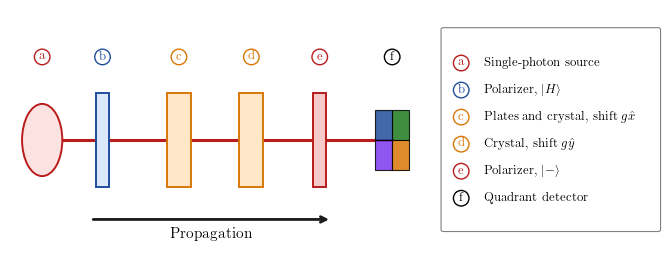

In [81]:
# ---------- Fig. 4: photonic setup ----------
fig = plt.figure(figsize=(6.4, 2.6))
ax = fig.add_axes([0, 0.0, 0.66, 1]); ax.set_xlim(0, 10.5); ax.set_ylim(0, 3.6); ax.axis('off')
ax.plot([0.7, 9.5], [1.8, 1.8], color=RED, lw=2.2, zorder=1)
ax.add_patch(Circle((0.8, 1.8), 0.5, fc='#fde2e2', ec=RED, lw=1.4, zorder=3)); letter(ax, 0.8, 2.95, 'a', RED)
comps = [(2.3, 0.32, '#dbe7fb', BLUE, 'b'), (4.2, 0.6, '#fde7c7', ORANGE, 'c'), (6.0, 0.6, '#fde7c7', ORANGE, 'd'), (7.7, 0.32, '#f8c9c9', RED, 'e')]
for x, w, fc, ec, l in comps:
    ax.add_patch(Rectangle((x - w/2, 1.15), w, 1.3, fc=fc, ec=ec, lw=1.4, zorder=3)); letter(ax, x, 2.95, l, ec)
qx, qy = 9.5, 1.8
for dx, dy, c in [(0, 0, GREEN), (-0.42, 0, BLUE), (-0.42, -0.42, PURPLE), (0, -0.42, ORANGE)]:
    ax.add_patch(Rectangle((qx + dx, qy + dy), 0.42, 0.42, fc=c, ec='k', lw=0.8, alpha=0.85, zorder=3))
letter(ax, 9.5, 2.95, 'f', 'k')
ax.annotate('', xy=(8, 0.7), xytext=(2, 0.7), arrowprops=dict(arrowstyle='->', lw=2.0, color='0.1'))
ax.text(5, 0.5, 'Propagation', ha='center', va='center', fontsize=11, color='0.0')
lg = fig.add_axes([0.67, 0.14, 0.35, 0.8]); lg.axis('off'); lg.set_xlim(0, 1); lg.set_ylim(0, 1)
lg.add_patch(FancyBboxPatch((0.02, 0.02), 0.96, 0.96, boxstyle='round,pad=0.01', fc='white', ec='0.5', lw=0.8))
items = [('a', RED, 'Single-photon source'), ('b', BLUE, r'Polarizer, $|H\rangle$'), ('c', ORANGE, r'Plates and crystal, shift $g\hat{x}$'),
         ('d', ORANGE, r'Crystal, shift $g\hat{y}$'), ('e', RED, r'Polarizer, $|-\rangle$'), ('f', 'k', r'Quadrant detector')]
for k, (l, c, t) in enumerate(items):
    y = 0.82 - k * 0.13; letter(lg, 0.1, y, l, c); lg.text(0.2, y, t, va='center', fontsize=9)
save(fig, 'fig4'); plt.show()

In [32]:
ket = lambda a: np.array([np.cos(a), np.sin(a)], complex)      # linear polarization at angle a (0 = H, pi/2 = V)
P = proj

def inst(u, e=0.0, phi=0.0):
    # Gaussian pointer, shift u = g/sigma, sign readout with flip probability e, birefringent phase phi
    kap = np.exp(-u**2 / 8)
    Delta = (1 - 2*e) * (2 * norm.cdf(u) - 1)
    gam = (1 - 2*e) * kap * (2 * norm.cdf(u / 2) - 1)
    return Delta, gam, kap, phi

def Lmap(r, Pi, ins):
    # weighted map of Eq. (56); the phase phi multiplies beta by e^{i phi}, so gamma -> gamma e^{-i phi}
    Delta, gam, kap, phi = ins; Q = I2 - Pi
    return Delta * Pi @ r @ Pi + gam * (np.exp(-1j * phi) * Q @ r @ Pi + np.exp(1j * phi) * Pi @ r @ Q)

def eps_bound(i1, i2, W1=1.0, W2=1.0):
    # Eq. (55) with p_d = (1 - |kappa|)/2 from Lemma 3
    pd1, pd2 = (1 - i1[2]) / 2, (1 - i2[2]) / 2
    return 2*W1*pd1*abs(i2[0]) + 2*abs(i1[0])*W2*pd2 + 4*W1*W2*pd1*pd2

def C(u, p0=0, pn=0, d1=0, d2=0, df=0, e=0, phi=0, eta=1):
    # exact quantum correlation, Eq. (57), and bound epsilon, Eq. (55), for the photonic test
    rho = depol(P(ket(0)), p0)
    P1 = P(ket(np.pi/4 + d1)); P2 = P(ket(np.pi/2 + d2)); Pf = P(ket(-np.pi/4 + df))
    i1, i2 = inst(u, e, phi), inst(u, e, phi)
    r = depol(Lmap(rho, P1, i1), pn); r = depol(Lmap(r, P2, i2), pn)
    return eta * np.trace(Pf @ r).real, eta * eps_bound(i1, i2)

u = 1e-3
Dl, gl, kl, _ = inst(u)
print(f"Small-u behaviour at u = {u}:  Delta/u = {Dl/u:.6f} (sqrt(2/pi) = {np.sqrt(2/np.pi):.6f}),"
      f"  gamma/u = {gl/u:.6f} (1/sqrt(2 pi) = {1/np.sqrt(2*np.pi):.6f}),  p_d/u^2 = {(1-kl)/2/u**2:.6f} (1/16 = 0.0625)")

Small-u behaviour at u = 0.001:  Delta/u = 0.797884 (sqrt(2/pi) = 0.797885),  gamma/u = 0.398942 (1/sqrt(2 pi) = 0.398942),  p_d/u^2 = 0.062500 (1/16 = 0.0625)


## Sec. VI B: Ideal performance (Eq. (64))

Leading order: $\mathcal C\simeq-u^2/(4\pi)\approx-0.080\,u^2$ and $\varepsilon\simeq\frac14\sqrt{2/\pi}\,u^3\approx0.20\,u^3$. The exact evaluation gives a violation for $u<0.381$ and the largest margin at $u=0.254$, with $\mathcal C=-5.03\times10^{-3}$, $\varepsilon=3.29\times10^{-3}$ and $M=1.74\times10^{-3}$.

In [34]:
x = 0.02; c_, e_ = C(x)
print(f"C/u^2 at u = {x}: {c_/x**2:.4f}   (-1/(4 pi) = {-1/(4*np.pi):.4f})")
print(f"eps/u^3 at u = {x}: {e_/x**3:.4f}   (sqrt(2/pi)/4 = {np.sqrt(2/np.pi)/4:.4f})")
u_thr = brentq(lambda v: sum(C(v)), 0.2, 1.0)
print(f"Violation (C < -eps) for all u < {u_thr:.3f}")
res = minimize_scalar(lambda v: sum(C(v)), bounds=(0.005, 1.2), method='bounded', options=dict(xatol=1e-8))
u_star = res.x; C_star, eps_star = C(u_star); M_ideal = -(C_star + eps_star)
print(f"Optimal u = {u_star:.4f}:  C = {C_star:.3e},  eps = {eps_star:.3e},  M = {M_ideal:.3e}")

C/u^2 at u = 0.02: -0.0796   (-1/(4 pi) = -0.0796)
eps/u^3 at u = 0.02: 0.1998   (sqrt(2/pi)/4 = 0.1995)
Violation (C < -eps) for all u < 0.381
Optimal u = 0.2542:  C = -5.033e-03,  eps = 3.293e-03,  M = 1.739e-03


## Sec. VI C: Statistics (Eq. (65))

$N=2W_1^2W_2^2\ln(2/\alpha)/M^2$ detected photons for significance level $\alpha=10^{-3}$.

In [36]:
N_runs = lambda M, W=1.0, alpha=1e-3: 2 * W**4 * np.log(2 / alpha) / M**2
print(f"Ideal setup: N = {N_runs(M_ideal):.2e} detected photons")

Ideal setup: N = 5.02e+06 detected photons


## Sec. VI D: Imperfections (Table I, Fig. 5)

Each imperfection is optimized over the pointer shift $u$. The knife-edge offset $o$ uses centered weights $w(\pm)=\pm1-m_0$, $m_0=2\Phi(-o)-1$, $W=1+|m_0|$ (Appendix D). The realistic combination uses $p=0.05$, $p_n=0.02$, misalignments of $\pm1^\circ$, $e=0.05$ and $\phi=0.05$.

In [38]:
def best(**kw):
    r = minimize_scalar(lambda v: sum(C(v, **kw)), bounds=(0.005, 1.2), method='bounded', options=dict(xatol=1e-8))
    c_, e_ = C(r.x, **kw); return r.x, -(c_ + e_), 1.0

def inst_offset(u, o):
    q0 = norm.cdf(-o); q1 = norm.cdf(u - o); m0 = 2*q0 - 1; kap = np.exp(-u**2 / 8)
    cplus = kap * norm.cdf(u/2 - o)                     # coherence factor integrated over x > o sigma
    gam = (1 - m0) * cplus + (-1 - m0) * (kap - cplus)  # centered weights w = +-1 - m0
    return (2*q1 - 1) - m0, gam, kap, 0.0, 1 + abs(m0)

def C_offset(u, o):
    rho = P(ket(0)); P1 = P(ket(np.pi/4)); P2 = P(ket(np.pi/2)); Pf = P(ket(-np.pi/4))
    D, gam, kap, ph, W = inst_offset(u, o); ins = (D, gam, kap, ph)
    r = Lmap(rho, P1, ins); r = Lmap(r, P2, ins)
    return np.trace(Pf @ r).real, eps_bound(ins, ins, W, W), W

def best_offset(o):
    r = minimize_scalar(lambda v: sum(C_offset(v, o)[:2]), bounds=(0.01, 1.2), method='bounded', options=dict(xatol=1e-8))
    c_, e_, W = C_offset(r.x, o); return r.x, -(c_ + e_), W

real = dict(p0=0.05, pn=0.02, d1=np.radians(1), d2=np.radians(-1), df=np.radians(1), e=0.05, phi=0.05)
rows = [("None", best()),
        ("Preparation noise p=0.1", best(p0=0.1)),
        ("Preparation noise p=0.3", best(p0=0.3)),
        ("Noise between elements p_n=0.05", best(pn=0.05)),
        ("Misalignment delta=5 deg", best(d1=np.radians(5), d2=np.radians(5), df=np.radians(5))),
        ("Birefringent phase phi=0.3", best(phi=0.3)),
        ("Readout flips e=0.05", best(e=0.05)),
        ("Readout flips e=0.15", best(e=0.15)),
        ("Knife-edge offset o=0.2", best_offset(0.2)),
        ("Realistic combination", best(**real))]
print(f"{'Imperfection':34s}{'Optimal u':>10s}{'Margin M':>12s}{'Runs N':>12s}")
for name, (u_, M_, W_) in rows:
    print(f"{name:34s}{u_:10.3f}{M_:12.3e}{N_runs(M_, W_):12.1e}")
N_real = N_runs(rows[-1][1][1])
print(f"\nMeasurement time at 1e5 detected photons per second: ideal {N_runs(M_ideal)/1e5:.0f} s, realistic {N_real/1e5:.0f} s,"
      f" and with half of the margin reserved for alignment (4 times the runs) {4*N_real/1e5/60:.0f} min")

Imperfection                       Optimal u    Margin M      Runs N
None                                   0.254   1.739e-03     5.0e+06
Preparation noise p=0.1                0.230   1.281e-03     9.3e+06
Preparation noise p=0.3                0.181   6.144e-04     4.0e+07
Noise between elements p_n=0.05        0.219   1.094e-03     1.3e+07
Misalignment delta=5 deg               0.251   1.664e-03     5.5e+06
Birefringent phase phi=0.3             0.211   9.884e-04     1.6e+07
Readout flips e=0.05                   0.230   1.149e-03     1.2e+07
Readout flips e=0.15                   0.180   4.252e-04     8.4e+07
Knife-edge offset o=0.2                0.217   1.235e-03     1.8e+07
Realistic combination                  0.204   8.053e-04     2.3e+07

Measurement time at 1e5 detected photons per second: ideal 50 s, realistic 234 s, and with half of the margin reserved for alignment (4 times the runs) 16 min


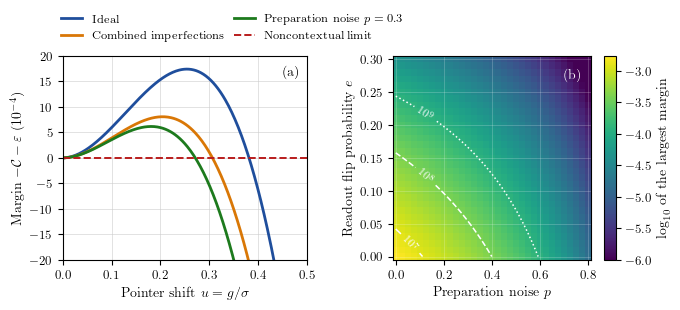

In [39]:
# ---------- Fig. 5: margins ----------
fig = plt.figure(figsize=(6.6, 3.0))
a = fig.add_axes([0.08, 0.17, 0.37, 0.68]); b = fig.add_axes([0.58, 0.17, 0.30, 0.68]); cb = fig.add_axes([0.9, 0.17, 0.018, 0.68])
uu = np.linspace(0.005, 0.5, 300)
for kw, c, l in ((dict(), BLUE, 'Ideal'), (real, ORANGE, 'Combined imperfections'), (dict(p0=0.3), GREEN, r'Preparation noise $p=0.3$')):
    a.plot(uu, np.array([-sum(C(x, **kw)) for x in uu]) * 1e4, color=c, lw=2, label=l)
a.axhline(0, color=RED, lw=1.4, ls='--', label='Noncontextual limit')
a.set_xlabel(r'Pointer shift $u=g/\sigma$'); a.set_ylabel(r'Margin $-\mathcal{C}-\varepsilon$ ($10^{-4}$)')
a.set_xlim(0, 0.5); a.set_ylim(-20, 20); a.grid(True, lw=0.4, color='0.8')
a.legend(loc='lower left', bbox_to_anchor=(-0.05, 1.02), ncol=2, frameon=False, handlelength=1.8, columnspacing=0.8, fontsize=8.5)
a.text(0.45, 16, '(a)')
ps = np.linspace(0, 0.8, 33); es = np.linspace(0, 0.3, 31); Mg = np.zeros((len(es), len(ps)))
for i, e in enumerate(es):
    for j, p in enumerate(ps):
        r = minimize_scalar(lambda x: sum(C(x, p0=p, e=e)), bounds=(0.003, 1.0), method='bounded')
        c_, ep = C(r.x, p0=p, e=e); Mg[i, j] = -(c_ + ep)
im = b.pcolormesh(ps, es, np.log10(np.clip(Mg, 1e-7, None)), cmap='viridis', shading='auto', vmin=-6, vmax=np.log10(Mg.max()))
Nr = 2 * np.log(2 / 1e-3) / np.clip(Mg, 1e-12, None)**2
cs = b.contour(ps, es, np.log10(Nr), levels=[7, 8, 9], colors=['w', 'w', 'w'], linewidths=1.1, linestyles=['-', '--', ':'])
b.clabel(cs, fmt={7: r'$10^7$', 8: r'$10^8$', 9: r'$10^9$'}, fontsize=8)
b.grid(True, color='w', lw=0.4, alpha=0.35); b.set_xlabel(r'Preparation noise $p$'); b.set_ylabel(r'Readout flip probability $e$')
b.text(0.7, 0.27, '(b)', color='w')
cbar = fig.colorbar(im, cax=cb); cbar.set_label(r'$\log_{10}$ of the largest margin')
save(fig, 'fig5'); plt.show()

## Sec. VI E: Alignment of the detector and of the crystals (Eqs. (66)-(69))

All pointer integrals are exact. For two Gaussian branches with shifts $\vec a$ and $\vec b$, $\varphi(\vec x-\vec a)\varphi(\vec x-\vec b)=e^{-|\vec a-\vec b|^2/8}\,\mathcal N(\vec x;(\vec a+\vec b)/2,\mathbb 1)$ in units of $\sigma$, so sign correlations along any pair of orthogonal axes are products of $2\Phi(\cdot)-1$. The mismatch probability $P_{\rm mis}$, which involves wedges, is computed by a one-dimensional quadrature.

We check that $P_{\rm mis}=2\vartheta/\pi$ to four digits at $u=0.254$, that $\mathcal C_\vartheta-\mathcal C$ is only about $10^{-6}$ even at $\vartheta=10$ mrad, that keeping half the ideal margin needs $\vartheta\le0.68$ mrad, and that the violation is lost at $\vartheta=1.4$ mrad. Finally we compute the effect of a tilt $\vartheta'$ of the second walk-off direction on the quantum correlation.

In [41]:
u0 = 0.254
rho = P(ket(0)); P1 = P(ket(np.pi/4)); P2 = P(ket(np.pi/2)); Pf = P(ket(-np.pi/4)); Q1 = I2 - P1; Q2 = I2 - P2

def branches(tilt=0.0):
    s, c = np.sin(tilt), np.cos(tilt)
    return [(Q2 @ Q1, np.array([0, 0])), (Q2 @ P1, np.array([u0, 0])),
            (P2 @ Q1, np.array([u0*s, u0*c])), (P2 @ P1, np.array([u0 + u0*s, u0*c]))]

def sign_corr(theta=0.0, tilt=0.0, postselect=True):
    # E[s1 s2 ; f] with knife edges rotated by theta, exact
    R = np.array([[np.cos(theta), np.sin(theta)], [-np.sin(theta), np.cos(theta)]])
    tot = 0.0
    for Oa, A in branches(tilt):
        for Ob, B in branches(tilt):
            M_ = Pf if postselect else I2
            coef = np.trace(M_ @ Oa @ rho @ Ob.conj().T).real
            m = R @ ((A + B) / 2)
            tot += coef * np.exp(-np.sum((A - B)**2) / 8) * (2*norm.cdf(m[0]) - 1) * (2*norm.cdf(m[1]) - 1)
    return tot

yq = np.linspace(-8, 8, 200001); dy = yq[1] - yq[0]
def P_mis(theta):
    # probability (no postselection) that at least one recorded sign differs from the aligned one
    tt = np.tan(theta); tot = 0.0
    for Oa, A in branches():
        for Ob, B in branches():
            coef = np.trace(Oa @ rho @ Ob.conj().T).real
            k = np.exp(-np.sum((A - B)**2) / 8); mx, my = (A + B) / 2
            # x-wedge: sgn x differs from sgn(x cos + y sin) iff x lies between 0 and -y tan(theta)
            lo, hi = np.minimum(0, -yq*tt), np.maximum(0, -yq*tt)
            tot += coef * k * np.sum(norm.pdf(yq, my, 1) * (norm.cdf(hi, mx, 1) - norm.cdf(lo, mx, 1))) * dy
            # y-wedge: sgn y differs from sgn(-x sin + y cos) iff y lies between 0 and x tan(theta)
            lo, hi = np.minimum(0, yq*tt), np.maximum(0, yq*tt)
            tot += coef * k * np.sum(norm.pdf(yq, mx, 1) * (norm.cdf(hi, my, 1) - norm.cdf(lo, my, 1))) * dy
    return tot   # the two wedges overlap only near the origin, a correction of order theta^2

C0 = sign_corr(); c_m, e_m = C(u0)
print(f"Aligned sign correlation at u = {u0}: {C0:.6e} (model of Eq. (57): {c_m:.6e})")
for th in (1e-4, 3e-4, 1e-3, 3e-3, 1e-2):
    print(f"theta = {th*1e3:5.1f} mrad:  P_mis = {P_mis(th):.4e}   2 theta/pi = {2*th/np.pi:.4e}   "
          f"C_theta - C = {sign_corr(th) - C0:+.2e}")
M0 = -(c_m + e_m)
print(f"\nMargin at u = {u0}: M = {M0:.3e}")
th_half = brentq(lambda th: 2*P_mis(th) - M0/2, 1e-5, 1e-2)
th_lost = brentq(lambda th: 2*P_mis(th) - M0, 1e-5, 1e-2)
print(f"Half of the margin kept for theta <= {th_half*1e3:.2f} mrad = {np.degrees(th_half):.3f} deg"
      f"   (pi M/8 = {np.pi*M0/8*1e3:.2f} mrad)")
print(f"Violation lost at theta = {th_lost*1e3:.2f} mrad   (pi M/4 = {np.pi*M0/4*1e3:.2f} mrad)")

Aligned sign correlation at u = 0.254: -5.024819e-03 (model of Eq. (57): -5.024819e-03)
theta =   0.1 mrad:  P_mis = 6.3659e-05   2 theta/pi = 6.3662e-05   C_theta - C = +1.01e-10
theta =   0.3 mrad:  P_mis = 1.9098e-04   2 theta/pi = 1.9099e-04   C_theta - C = +9.05e-10
theta =   1.0 mrad:  P_mis = 6.3659e-04   2 theta/pi = 6.3662e-04   C_theta - C = +1.01e-08
theta =   3.0 mrad:  P_mis = 1.9098e-03   2 theta/pi = 1.9099e-03   C_theta - C = +9.05e-08
theta =  10.0 mrad:  P_mis = 6.3660e-03   2 theta/pi = 6.3662e-03   C_theta - C = +1.01e-06

Margin at u = 0.254: M = 1.739e-03
Half of the margin kept for theta <= 0.68 mrad = 0.039 deg   (pi M/8 = 0.68 mrad)
Violation lost at theta = 1.37 mrad   (pi M/4 = 1.37 mrad)


theta =   0.3 mrad:  P_mis = 1.9098e-04   2 theta/pi = 1.9099e-04   C_theta - C = +9.05e-10


theta =   1.0 mrad:  P_mis = 6.3659e-04   2 theta/pi = 6.3662e-04   C_theta - C = +1.01e-08


theta =   3.0 mrad:  P_mis = 1.9098e-03   2 theta/pi = 1.9099e-03   C_theta - C = +9.05e-08


theta =  10.0 mrad:  P_mis = 6.3660e-03   2 theta/pi = 6.3662e-03   C_theta - C = +1.01e-06

Margin at u = 0.254: M = 1.739e-03


Half of the margin kept for theta <= 0.68 mrad = 0.039 deg   (pi M/8 = 0.68 mrad)
Violation lost at theta = 1.37 mrad   (pi M/4 = 1.37 mrad)


In [42]:
print("Tilt of the second walk-off direction (quantum correlation only):")
for tp in (1e-3, 3e-3, 1e-2):
    print(f"  theta' = {tp*1e3:4.1f} mrad: relative change of C = {(sign_corr(tilt=tp) - C0)/abs(C0):.1e}")

Tilt of the second walk-off direction (quantum correlation only):
  theta' =  1.0 mrad: relative change of C = 3.3e-05
  theta' =  3.0 mrad: relative change of C = 1.0e-04
  theta' = 10.0 mrad: relative change of C = 3.8e-04


## Appendix B: Pure qubit states satisfy $\mathrm{KC}_4=\mathrm{KC}$ (Remark 1, Proposition 3)

We draw 400 random tuples of three to five pure qubit states containing an antipodal pair. The remaining Bloch vectors lie either on a half great circle through the pair, which makes the tuple KD classical, or are randomly perturbed. No tuple lies in $\mathrm{KC}_4$ without lying in $\mathrm{KC}_6$.

In [44]:
def bloch_ket(nv):
    th = np.arccos(np.clip(nv[2], -1, 1)); ph = np.arctan2(nv[1], nv[0])
    return np.array([np.cos(th/2), np.exp(1j*ph) * np.sin(th/2)])
rng_b = np.random.default_rng(3); bad = 0; n_kc4 = 0
for _ in range(400):
    n = rng_b.integers(3, 6); m = rng_b.normal(size=3); m /= np.linalg.norm(m); vs = [m, -m]
    aa = rng_b.normal(size=3); aa -= aa.dot(m) * m; aa /= np.linalg.norm(aa)
    for k in range(n - 2):
        t_ = rng_b.uniform(0.1, np.pi - 0.1); v = np.cos(t_) * m + np.sin(t_) * aa
        if rng_b.random() < 0.5: v = v + rng_b.normal(scale=0.3, size=3)
        vs.append(v / np.linalg.norm(v))
    st = [proj(bloch_ket(v)) for v in vs]
    a4 = in_KC(st, 4); n_kc4 += a4; bad += a4 and not in_KC(st, 6)
print(f"400 tuples tested, {n_kc4} in KC_4, of which {bad} are not in KC_6")

400 tuples tested, 174 in KC_4, of which 0 are not in KC_6


## Appendix D: Gaussian pointers with sign readout

First, we compare the coarse-grained map $\mathcal L$ of Eq. (56), with the parameters of Eq. (63), readout flips and a birefringent phase, against a direct numerical integration over the pointer position. Second, we check the bound of Theorem 6 in twenty thousand random configurations in which all states and projectors commute, with random diagonal instruments and random noise, where the bound must never be violated.

In [46]:
x = np.arange(-12, 12, 2e-4) + 1e-4; dx = 2e-4; uu_, ph_, ee_ = 0.7, 0.3, 0.1
phi_x = lambda q: (2*np.pi)**-0.25 * np.exp(-q**2 / 4)
rho_t = P(np.array([0.6, 0.8], complex)); Pi_t = P(ket(0.4)); Q_t = I2 - Pi_t
w = np.sign(x) * (1 - 2*ee_)
A_ = np.sum(w * phi_x(x)**2) * dx; B_ = np.sum(w * phi_x(x - uu_)**2) * dx; G_ = np.sum(w * phi_x(x) * phi_x(x - uu_)) * dx
L_direct = B_ * Pi_t @ rho_t @ Pi_t + A_ * Q_t @ rho_t @ Q_t + G_ * (np.exp(-1j*ph_) * Q_t @ rho_t @ Pi_t + np.exp(1j*ph_) * Pi_t @ rho_t @ Q_t)
print(f"Largest deviation between direct integration and Eq. (56): {np.abs(L_direct - Lmap(rho_t, Pi_t, inst(uu_, ee_, ph_))).max():.1e}")

rng_d = np.random.default_rng(4); viol = 0; worst = np.inf
def diag_noise(r):
    # random noise that keeps diagonal states diagonal: depolarization followed by dephasing
    r = depol(r, rng_d.uniform(0, 0.5)); q = rng_d.uniform(0, 1)
    return (1 - q) * r + q * np.diag(np.diag(r))
for _ in range(20000):
    d = np.diag(rng_d.dirichlet([1, 1])).astype(complex)
    Ps = [np.diag([1., 0]) if rng_d.random() < .5 else np.diag([0, 1.]) for _ in range(3)]
    i1 = inst(rng_d.uniform(0, 2), rng_d.uniform(0, .4), rng_d.uniform(0, 6))
    i2 = inst(rng_d.uniform(0, 2), rng_d.uniform(0, .4), rng_d.uniform(0, 6))
    r = diag_noise(d); r = diag_noise(Lmap(r, Ps[0], i1)); r = diag_noise(Lmap(r, Ps[1], i2))
    c_ = np.sign(i1[0] * i2[0]) * np.trace(Ps[2] @ r).real; e_ = eps_bound(i1, i2)
    worst = min(worst, c_ + e_); viol += c_ < -e_ - 1e-12
print(f"Commuting configurations: {viol} violations in 20000, smallest C + eps = {worst:.2e} (>= 0)")

Largest deviation between direct integration and Eq. (56): 2.8e-10
Commuting configurations: 0 violations in 20000, smallest C + eps = 5.69e-08 (>= 0)


All figures have been written to `fig1.pdf` to `fig5.pdf` (and PNG copies) in the working directory.